In [1]:
# The sample Superstore dataset contains retail sales information, including order dates, shipping modes, customer segments, product categories, sales, discounts, & profits. The purpose of this analysis is to explore the data, identify patterns, handle missing values, & understand the factors associated with sales and profitability.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Retail Sales.csv")

In [4]:
print(df.head())

print()

print("Dataset shape:", df.shape)

print()

print("Column information:")
df.info()

print()

print("Summary of numeric columns:")
print(df.describe())

  Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
1      2  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
2      3  CA-2017-138688   6/12/2017   6/16/2017    Second Class    DV-13045   
3      4  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
4      5  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0     42420.0   South  FUR

In [5]:
print("Missing values before cleaning:")
print(df.isna().sum())

Missing values before cleaning:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [6]:
if "Postal Code" in df.columns:
  # Using 0 as a placeholder for an unknown postal code, not a real postal code
  df["Postal Code"] = df["Postal Code"].fillna(0)

# Remove only exact duplicate rows if present
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)
df = df.drop_duplicates()

print()

print("Missing values after cleaning:")
print(df.isna().sum())

Exact duplicate rows: 504

Missing values after cleaning:
Row ID             0
Order ID           0
Order Date       302
Ship Date        302
Ship Mode        302
Customer ID      302
Customer Name    302
Segment          302
Country          302
City             302
State            302
Postal Code        0
Region           302
Product ID       302
Category         302
Sub-Category     302
Product Name     302
Sales            302
Quantity         302
Discount         302
Profit           302
dtype: int64


In [7]:
# Convert date columns to datetime where they exist
for date_col in ["Order Date", "Ship Date"]:
    if date_col in df.columns:
        df[date_col] = pd.to_datetime(df[date_col])

# Standardize whitespace in categorical/text columns.
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()

# Keep rows with a valid order date because the time analysis depends on it.
if "Order Date" in df.columns:
    df = df.dropna(subset=["Order Date"]).copy()

print(df[["Order Date", "Ship Date"]].head())


  Order Date  Ship Date
0 2017-11-08 2017-11-11
1 2017-11-08 2017-11-11
2 2017-06-12 2017-06-16
3 2016-10-11 2016-10-18
4 2016-10-11 2016-10-18


In [8]:
# Filter rows using multiple conditions
high_value_profitable = df[(df["Sales"] > 500) & (df["Profit"] > 0)]
print("Orders with sales > 500 and positive profit:", len(high_value_profitable))
print(high_value_profitable[["Order ID", "Category", "Sales", "Discount", "Profit"]])


Orders with sales > 500 and positive profit: 883
            Order ID         Category     Sales  Discount    Profit
1     CA-2017-152156        Furniture   731.940       0.0  219.5820
7     CA-2015-115812       Technology   907.152       0.2   90.7152
10    CA-2015-115812        Furniture  1706.184       0.2   85.3092
11    CA-2015-115812       Technology   911.424       0.2   68.3568
16    CA-2015-105893  Office Supplies   665.880       0.0   13.3176
...              ...              ...       ...       ...       ...
9929  CA-2017-129630       Technology  2799.960       0.2  944.9865
9942  CA-2015-143371  Office Supplies   998.820       0.0   29.9646
9947  CA-2018-121559        Furniture  1925.880       0.0  539.2464
9948  CA-2018-121559  Office Supplies  2405.200       0.0  793.7160
9968  CA-2018-153871  Office Supplies   735.980       0.0  331.1910

[883 rows x 5 columns]


In [9]:
# Create a column with .apply() and a lambda, labeling each order's sales amount as High or Regular
df["Sales Level"] = df["Sales"].apply(lambda sales: "High" if sales >= 500 else "Regular")
print(df[["Sales", "Sales Level"]])

         Sales Sales Level
0     261.9600     Regular
1     731.9400        High
2      14.6200     Regular
3     957.5775        High
4      22.3680     Regular
...        ...         ...
9989   25.2480     Regular
9990   91.9600     Regular
9991  258.5760     Regular
9992   29.6000     Regular
9993  243.1600     Regular

[9994 rows x 2 columns]


In [10]:
# Creating a different new column using .apply() with a function
def profit_status(profit):
  if profit > 0:
    return "Profitable"
  elif profit < 0:
    return "Loss"
  return "Break-even"

df["Profit Status"] = df["Profit"].apply(profit_status)
print(df[["Profit", "Profit Status"]])

        Profit Profit Status
0      41.9136    Profitable
1     219.5820    Profitable
2       6.8714    Profitable
3    -383.0310          Loss
4       2.5164    Profitable
...        ...           ...
9989    4.1028    Profitable
9990   15.6332    Profitable
9991   19.3932    Profitable
9992   13.3200    Profitable
9993   72.9480    Profitable

[9994 rows x 2 columns]


In [11]:
# By using Numpy operation, applying a condition across a whole column. Use it to flag orders with a discount of 20% or above
df["High Discount"] = np.where(df["Discount"] >= 0.20, "Yes", "No")
print(df[["Discount", "High Discount"]])

      Discount High Discount
0         0.00            No
1         0.00            No
2         0.00            No
3         0.45           Yes
4         0.20           Yes
...        ...           ...
9989      0.20           Yes
9990      0.00            No
9991      0.20           Yes
9992      0.00            No
9993      0.00            No

[9994 rows x 2 columns]


In [12]:
# Sort the data with .sort_values(), by at least 2 columns at once. Sort first by category alphabetically, then by sales from highest to lowest within each category, (ascending=[True, False]) sets the direction for each column
sorted_df = df.sort_values(["Category", "Sales"], ascending=[True, False])
print(sorted_df[["Category", "Product Name", "Sales", "Profit"]])

        Category                                       Product Name     Sales  \
7243   Furniture       HON 5400 Series Task Chairs for Big and Tall  4416.174   
9741   Furniture  Riverside Palais Royal Lawyers Bookcase, Royal...  4404.900   
9639   Furniture  Chromcraft Bull-Nose Wood Oval Conference Tabl...  4297.644   
5917   Furniture  Riverside Palais Royal Lawyers Bookcase, Royal...  4228.704   
6535   Furniture              DMI Eclipse Executive Suite Bookcases  4007.840   
...          ...                                                ...       ...   
9163  Technology                          Maxell 4.7GB DVD+R 5/Pack     2.376   
7990  Technology                          Maxell 4.7GB DVD+R 5/Pack     1.980   
9545  Technology                          Maxell 4.7GB DVD+R 5/Pack     1.980   
7900  Technology                          Maxell 4.7GB DVD-R 5/Pack     1.584   
2761  Technology                          Maxell 4.7GB DVD-R 5/Pack     0.990   

         Profit  
7243  -63

In [13]:
# By using list comprehension creates a list where we select numeric columns for the correlation analysis, excluding Postal Code and Row ID because they are identifiers rather than meaningful measures
numeric_cols = [col for col in df.select_dtypes(include=np.number).columns if col not in ["Postal Code", "Row ID"]]
print("Numeric columns for analysis:", numeric_cols)

Numeric columns for analysis: ['Sales', 'Quantity', 'Discount', 'Profit']


In [14]:
# Group by one category and calculate total sales for each product category
sales_by_category = df.groupby("Category")["Sales"].sum()
print("Total sales by category:")
print(sales_by_category.sort_values(ascending=False))

Total sales by category:
Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [15]:
# Calculate several statistics at once, total sales, average sales, total profit, average profit, and order-line count by category
category_summary = df.groupby("Category").agg(
    total_sales=("Sales", "sum"),
    average_sales=("Sales", "mean"),
    total_profit=("Profit", "sum"),
    average_profit=("Profit", "mean"),
    order_lines=("Order ID", "count")
)
print(category_summary)

                 total_sales  average_sales  total_profit  average_profit  \
Category                                                                    
Furniture        741999.7953     349.834887    18451.2728        8.699327   
Office Supplies  719047.0320     119.324101   122490.8008       20.327050   
Technology       836154.0330     452.709276   145454.9481       78.752002   

                 order_lines  
Category                      
Furniture               2121  
Office Supplies         6026  
Technology              1847  


In [16]:
# Reorder grouped results by total sales from highest to lowest
category_summary = category_summary.sort_values("total_sales", ascending=False)
print(category_summary)

                 total_sales  average_sales  total_profit  average_profit  \
Category                                                                    
Technology       836154.0330     452.709276   145454.9481       78.752002   
Furniture        741999.7953     349.834887    18451.2728        8.699327   
Office Supplies  719047.0320     119.324101   122490.8008       20.327050   

                 order_lines  
Category                      
Technology              1847  
Furniture               2121  
Office Supplies         6026  


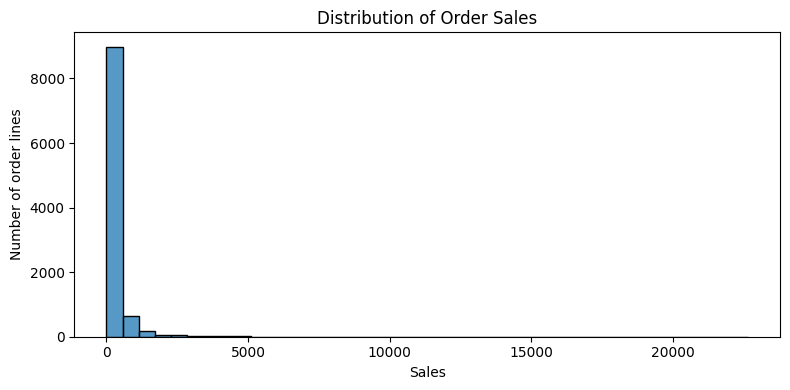

Interpretation: Sales are concentrated where the histogram has the tallest bars. A long tail to the right indicates that a small number of orders have much higher sales.


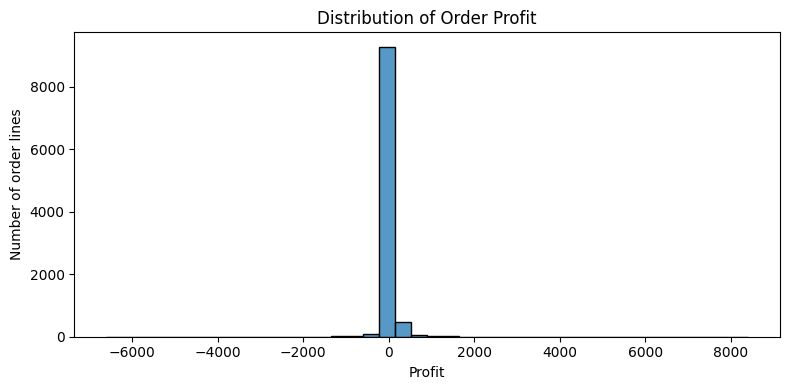

Interpretation: Bars below zero represent loss-making order lines; bars above zero represent profitable order lines. Check whether the distribution is balanced or skewed.


In [28]:
# Histogram 1: Sales distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["Sales"], bins=40)
plt.title("Distribution of Order Sales")
plt.xlabel("Sales")
plt.ylabel("Number of order lines")
plt.tight_layout()
plt.show()
print("Interpretation: Sales are concentrated where the histogram has the tallest bars. A long tail to the right indicates that a small number of orders have much higher sales.")

# Histogram 2: Profit distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["Profit"], bins=40)
plt.title("Distribution of Order Profit")
plt.xlabel("Profit")
plt.ylabel("Number of order lines")
plt.tight_layout()
plt.show()
print("Interpretation: Bars below zero represent loss-making order lines; bars above zero represent profitable order lines. Check whether the distribution is balanced or skewed.")


In [45]:
# Identify possible outliers using the IQR rule
# The IQR method is used to identify potential outliers in the Sales column. Q1 and Q3 represent the 25th and 75th percentiles, respectively, and the upper limit is calculated using Q3 + 1.5 × IQR. Sales values above this limit were classified as potential high-sales outliers. These values were examined separately rather than automatically removed because they may represent genuine large orders.
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
outliers = df[df["Sales"] > upper_limit]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print()
print("Upper outlier limit:", upper_limit)
print()
print("Number of possible high-sales outliers:", len(outliers))
print()
print(outliers[["Order ID", "Product Name", "Sales", "Profit"]].sort_values("Sales", ascending=False))


Q1: 17.28
Q3: 209.94
IQR: 192.66

Upper outlier limit: 498.93

Number of possible high-sales outliers: 1167

            Order ID                                       Product Name  \
2697  CA-2015-145317  Cisco TelePresence System EX90 Videoconferenci...   
6826  CA-2017-118689              Canon imageCLASS 2200 Advanced Copier   
8153  CA-2018-140151              Canon imageCLASS 2200 Advanced Copier   
2623  CA-2018-127180              Canon imageCLASS 2200 Advanced Copier   
4190  CA-2018-166709              Canon imageCLASS 2200 Advanced Copier   
...              ...                                                ...   
3731  CA-2016-109575                           Samsung Galaxy S4 Active   
2263  CA-2017-131065                      Logitech diNovo Edge Keyboard   
5619  US-2017-124163                     Logitech Wireless Headset h800   
2968  CA-2018-167941  1.7 Cubic Foot Compact "Cube" Office Refrigera...   
8594  CA-2018-159667                                    Motorola L

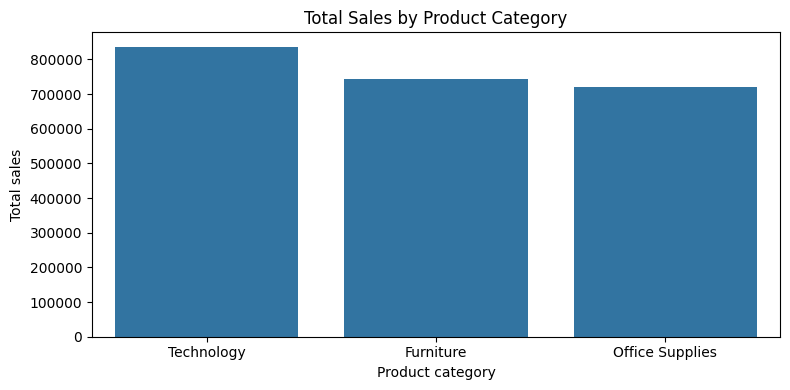

Interpretation: Technology has the highest total sales in this dataset. Sales totals show revenue volume, but do not alone tell us which category is most profitable.


In [36]:
# Chart 1: Total sales by category
plt.figure(figsize=(8, 4))
sns.barplot(data=category_summary.reset_index(), x="Category", y="total_sales")
plt.title("Total Sales by Product Category")
plt.xlabel("Product category")
plt.ylabel("Total sales")
plt.tight_layout()
plt.show()
best_sales_category = category_summary["total_sales"].idxmax()
print(f"Interpretation: {best_sales_category} has the highest total sales in this dataset. Sales totals show revenue volume, but do not alone tell us which category is most profitable.")


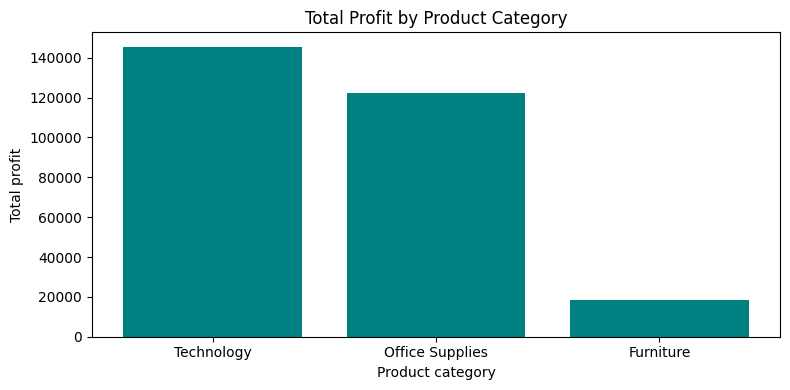

Interpretation: Technology has the highest total profit. Compare this chart with the sales chart because high sales do not always mean high profit.


In [37]:
# Chart 2: Total profit by category
profit_plot = category_summary["total_profit"].sort_values(ascending=False)
plt.figure(figsize=(8, 4))
plt.bar(profit_plot.index, profit_plot.values, color="teal")
plt.title("Total Profit by Product Category")
plt.xlabel("Product category")
plt.ylabel("Total profit")
plt.tight_layout()
plt.show()
best_profit_category = category_summary["total_profit"].idxmax()
print(f"Interpretation: {best_profit_category} has the highest total profit. Compare this chart with the sales chart because high sales do not always mean high profit.")

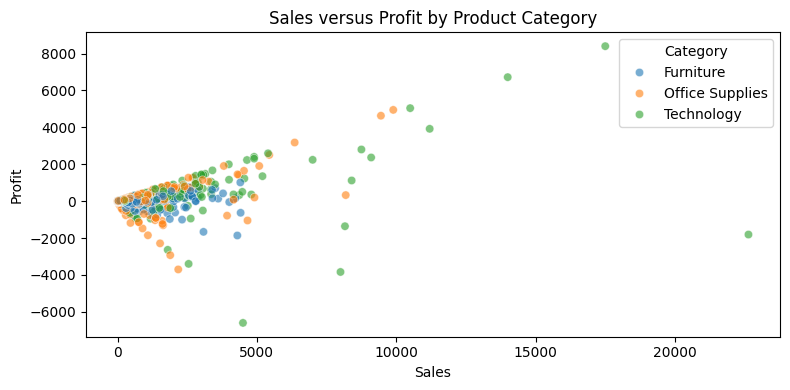

Interpretation: Each point is an order line. Points below zero on the y-axis represent losses. Look for high-sales orders that still have negative profit.


In [38]:
# Chart 3: Sales versus profit by order line
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="Sales", y="Profit", hue="Category", alpha=0.6)
plt.title("Sales versus Profit by Product Category")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()
print("Interpretation: Each point is an order line. Points below zero on the y-axis represent losses. Look for high-sales orders that still have negative profit.")

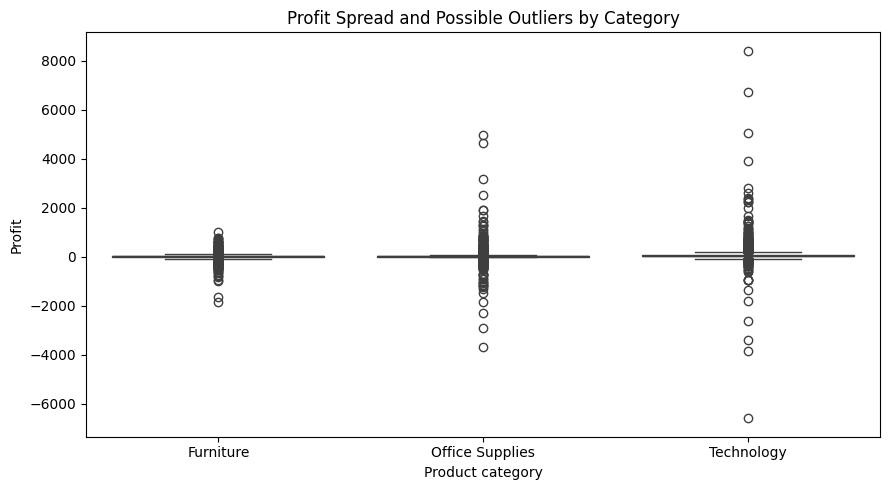

Interpretation: The line inside each box is the median profit. Points beyond the whiskers are possible outliers. Categories with values below zero include loss-making order lines.


In [43]:
# Boxplot of profit grouped by category
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Category", y="Profit")
plt.title("Profit Spread and Possible Outliers by Category")
plt.xlabel("Product category")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()
print("Interpretation: The line inside each box is the median profit. Points beyond the whiskers are possible outliers. Categories with values below zero include loss-making order lines.")

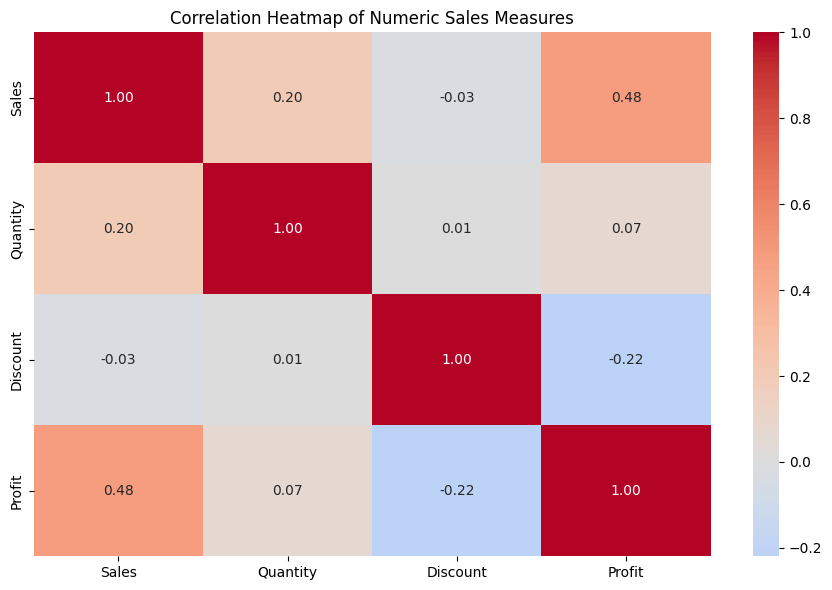

Interpretation: Correlation ranges from -1 to +1. Values near +1 show a positive linear relationship, values near -1 show a negative relationship, and values near 0 show little linear relationship. Correlation does not prove causation.


In [44]:
# Correlation heatmap across numeric measures
correlation = df[numeric_cols].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap of Numeric Sales Measures")
plt.tight_layout()
plt.show()
print("Interpretation: Correlation ranges from -1 to +1. Values near +1 show a positive linear relationship, values near -1 show a negative relationship, and values near 0 show little linear relationship. Correlation does not prove causation.")

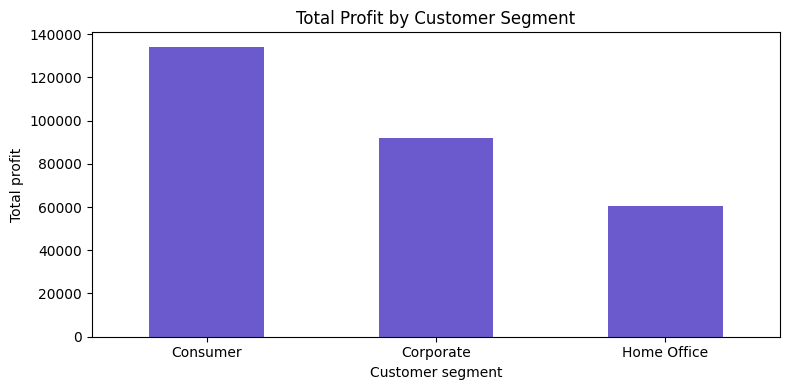

Interpretation: Consumer contributes the highest total profit among the customer segments in this dataset. Total profit may also depend on how many order lines each segment has.


In [46]:
# Chart 5: Total profit by customer segment
segment_profit = df.groupby("Segment")["Profit"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 4))
segment_profit.plot(kind="bar", color="slateblue")
plt.title("Total Profit by Customer Segment")
plt.xlabel("Customer segment")
plt.ylabel("Total profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(f"Interpretation: {segment_profit.idxmax()} contributes the highest total profit among the customer segments in this dataset. Total profit may also depend on how many order lines each segment has.")

               average_discount  average_profit  total_profit  order_lines
High Discount                                                             
No                     0.003479       67.037980   331435.7717         4944
Yes                    0.305721       -8.918564   -45038.7500         5050



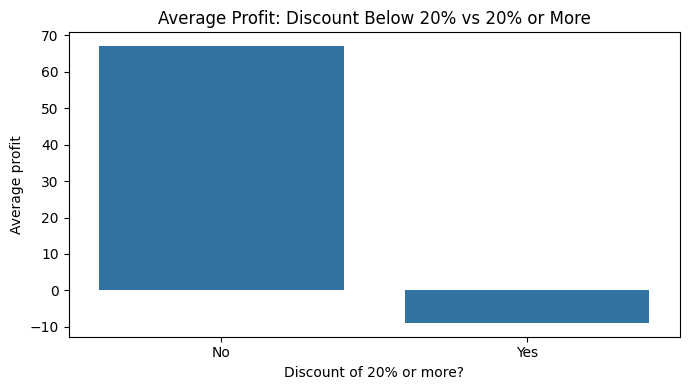

Interpretation: Compare the average profit for the two discount groups. If the high-discount group has lower average profit, the dataset shows an association, not proof that discount alone caused it.


In [50]:
# Investigate discount and profit
discount_summary = df.groupby("High Discount").agg(
    average_discount=("Discount", "mean"),
    average_profit=("Profit", "mean"),
    total_profit=("Profit", "sum"),
    order_lines=("Order ID", "count")
)
print(discount_summary)

print()

plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="High Discount", y="Profit", errorbar=None)
plt.title("Average Profit: Discount Below 20% vs 20% or More")
plt.xlabel("Discount of 20% or more?")
plt.ylabel("Average profit")
plt.tight_layout()
plt.show()
print("Interpretation: Compare the average profit for the two discount groups. If the high-discount group has lower average profit, the dataset shows an association, not proof that discount alone caused it.")

In [57]:
# Question 1: Which category has the highest sales and profit?
print("Q1 — Highest total sales category:", category_summary["total_sales"].idxmax())
print("Q1 — Highest total profit category:", category_summary["total_profit"].idxmax())
print("Total sales and total profit by category:")
display(category_summary[["total_sales", "total_profit"]])

# Question 2: How do profit totals differ across segments and regions?
print("\nQ2 — Total profit by segment:")
display(df.groupby("Segment")["Profit"].sum().sort_values(ascending=False))
print("Q2 — Total profit by region:")
display(df.groupby("Region")["Profit"].sum().sort_values(ascending=False))

# Question 3: What is the relationship between discount and profit?
print("\nQ3 — Correlation between discount and profit:", round(df["Discount"].corr(df["Profit"]), 3))
print("Q3 — Average profit by discount group:")
display(df.groupby("High Discount")["Profit"].mean())
print("Q3 — Number of high-sales outliers identified:", len(outliers))

Q1 — Highest total sales category: Technology
Q1 — Highest total profit category: Technology
Total sales and total profit by category:


,total_sales,total_profit
Category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008



Q2 — Total profit by segment:


,Profit
Segment,
Consumer,134119.2092
Corporate,91979.1340
Home Office,60298.6785


Q2 — Total profit by region:


,Profit
Region,
West,108418.4489
East,91522.7800
South,46749.4303
Central,39706.3625



Q3 — Correlation between discount and profit: -0.219
Q3 — Average profit by discount group:


,Profit
High Discount,
No,67.037980
Yes,-8.918564


Q3 — Number of high-sales outliers identified: 1167
